# 04 — Monitoring (2015 as four production quarters)

**Question for this notebook:** if the champion scorecard had been deployed at the start of 2015, what would quarterly monitoring have shown, when would we have known it, and what would we have concluded?

Reference sample = development train (2012-Q4–2013). The model, risk grades and recalibration shift are loaded frozen from earlier notebooks.

In [1]:
%load_ext autoreload
%autoreload 2

import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
from src import monitoring as mon
from src import validation as val
from src.data_prep import load_model_data, split_development, sql_connection
from src.features import add_derived_features

pd.set_option("display.max_columns", 30)
TARGET = config.TARGET

data = add_derived_features(load_model_data())
train, valid = split_development(data)
monitoring = data[data["sample"] == "monitoring"].copy()

with open(config.ROOT / "models" / "champion_scorecard.pkl", "rb") as f:
    card = pickle.load(f)
with open(config.ROOT / "models" / "validation_artifacts.pkl", "rb") as f:
    artifacts = pickle.load(f)
grade_edges = artifacts["grade_edges"]

pd_reference = card.predict_pd(train)
monitoring["pd"] = card.predict_pd(monitoring)
monitoring["pd_recalibrated"] = expit(card.log_odds_bad(monitoring) + artifacts["intercept_shift_2014"])
monitoring["grade"] = val.assign_grades(monitoring["pd"], grade_edges)
gini_reference = val.gini(valid[TARGET], card.predict_pd(valid))
quarters = sorted(monitoring["issue_quarter"].unique())
print(f"Monitoring loans: {len(monitoring):,} in {quarters}; reference Gini (validation) {gini_reference:.4f}")

(CVXPY) Nov 23 10:31:38 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/home/sava/project/.venv/lib/python3.12/site-packages/highspy/_core.cpython-312-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


Monitoring loans: 282,848 in ['2015-Q1', '2015-Q2', '2015-Q3', '2015-Q4']; reference Gini (validation) 0.3258


## 1. Thresholds — declared before looking at the results
These are common industry conventions, not any specific bank's or regulator's standards; in practice they are agreed with the model owner and validation. Calibration needs **both** a significant Jeffreys test and a material gap, because with ~60–90k loans per quarter a p-value alone flags differences too small to matter.

In [2]:
mon.THRESHOLDS

,amber,red
metric,,
score PSI,0.10,0.25
feature CSI,0.10,0.25
Gini drop vs development (absolute),0.05,0.10
calibration: Jeffreys p-value (below),0.05,0.01
calibration: relative PD underestimation (above),0.05,0.10


## 2. Two kinds of monitoring and their time lag
- **Front-end stability** (score PSI, feature CSI) needs only application data → available at the end of each quarter.
- **Back-testing** (Gini, calibration) needs outcomes → for a 36-month loan, fully available only up to three years later.

The table shows how quickly defaults appear in the 2015 loans (months from issue to the last payment received, for loans that eventually defaulted). It shows how much of the eventual outcome an early back-test would already see.

In [3]:
bads = monitoring[monitoring[TARGET] == 1]
last_payment = pd.to_datetime(bads["last_pymnt_d"], format="%b-%Y")
issued = pd.to_datetime(bads["issue_date"])
months_to_last_payment = (last_payment.dt.year - issued.dt.year) * 12 + (last_payment.dt.month - issued.dt.month)
print(f"Defaults without a last payment date: {months_to_last_payment.isna().sum()}")

lag = pd.DataFrame({
    "defaults_with_last_payment_by_month_pct": [
        100 * (months_to_last_payment.fillna(0) <= m).mean() for m in (6, 12, 18, 24, 36)
    ]
}, index=pd.Index([6, 12, 18, 24, 36], name="months_on_book"))
lag.round(1)

Defaults without a last payment date: 200


,defaults_with_last_payment_by_month_pct
months_on_book,
6,12.5
12,35.3
18,58.9
24,77.9
36,99.2


## 3. Front-end stability: score PSI and feature CSI per quarter
Score PSI uses the training-sample PD deciles; CSI uses each feature's scorecard bins.

In [4]:
psi_edges = val.grade_edges(pd_reference, n_grades=10)
score_psi = pd.Series(
    {q: mon.score_psi(pd_reference, g["pd"], psi_edges) for q, g in monitoring.groupby("issue_quarter")},
    name="score_psi",
)

ref_bins = card.binning.transform(train[card.binning.variable_names], metric="bins")[card.features]
mon_bins = card.binning.transform(monitoring[card.binning.variable_names], metric="bins")[card.features]
mon_bins.index = monitoring.index
csi = mon.csi_by_period(ref_bins, mon_bins, monitoring["issue_quarter"])

display(score_psi.round(4).to_frame().T)
csi.round(4).sort_values(quarters[-1], ascending=False)

,2015-Q1,2015-Q2,2015-Q3,2015-Q4
score_psi,0.0169,0.0106,0.0047,0.0034


,2015-Q1,2015-Q2,2015-Q3,2015-Q4
percent_bc_gt_75,0.0252,0.0530,0.0717,0.0825
acc_open_past_24mths,0.0445,0.0682,0.0575,0.0545
dti,0.0514,0.0456,0.0456,0.0469
bc_open_to_buy,0.0060,0.0082,0.0208,0.0292
mths_since_recent_bc,0.0324,0.0316,0.0296,0.0259
mo_sin_rcnt_tl,0.0205,0.0121,0.0122,0.0250
fico_mid,0.0337,0.0279,0.0247,0.0233
mo_sin_old_il_acct,0.0116,0.0107,0.0155,0.0201
loan_to_income,0.0035,0.0076,0.0081,0.0180
tot_hi_cred_lim,0.0080,0.0106,0.0138,0.0126


## 4. Back-testing per quarter: discrimination and calibration

In [5]:
def backtest(df: pd.DataFrame, pd_col: str) -> dict:
    y, p = df[TARGET].to_numpy(), df[pd_col].to_numpy()
    n, d = len(y), int(y.sum())
    by_grade = val.calibration_table(y, p, df["grade"])
    grade_status = [
        mon.rag_calibration(r.jeffreys_p, r.odr_pct / r.mean_pd_pct - 1) for r in by_grade.itertuples()
    ]
    return {
        "loans": n,
        "defaults": d,
        "mean_pd_pct": 100 * p.mean(),
        "odr_pct": 100 * d / n,
        "relative_underestimation_pct": 100 * (d / n / p.mean() - 1),
        "jeffreys_p": val.jeffreys_pvalue(n, d, p.mean()),
        "grades_amber": grade_status.count("amber"),
        "grades_red": grade_status.count("red"),
    }

rows = {}
for q, g in monitoring.groupby("issue_quarter"):
    y, p = g[TARGET].to_numpy(), g["pd"].to_numpy()
    low, high = val.bootstrap_gini_ci(y, p, n_boot=100)
    rows[q] = {"gini": val.gini(y, p), "gini_ci_low": low, "gini_ci_high": high, **backtest(g, "pd")}
backtesting = pd.DataFrame(rows).T
backtesting["gini_drop"] = gini_reference - backtesting["gini"]
backtesting.round(4)

,gini,gini_ci_low,gini_ci_high,loans,defaults,mean_pd_pct,odr_pct,relative_underestimation_pct,jeffreys_p,grades_amber,grades_red,gini_drop
2015-Q1,0.3275,0.3153,0.3377,56568.0,8391.0,13.3097,14.8335,11.4483,0.0,0.0,6.0,-0.0017
2015-Q2,0.3323,0.3214,0.3439,64222.0,9878.0,13.1186,15.3810,17.2459,0.0,1.0,6.0,-0.0066
2015-Q3,0.3456,0.3350,0.3565,73569.0,10727.0,12.7354,14.5809,14.4910,0.0,2.0,6.0,-0.0198
2015-Q4,0.3400,0.3321,0.3474,88489.0,13154.0,12.5642,14.8651,18.3130,0.0,1.0,7.0,-0.0142


## 5. RAG summary per quarter

In [6]:
rag = pd.DataFrame(index=quarters)
rag["score_psi"] = score_psi.round(4)
rag["max_csi"] = csi.max().round(4)
rag["max_csi_feature"] = csi.idxmax()
rag["stability"] = [mon.worst([mon.rag_stability(a), mon.rag_stability(b)]) for a, b in zip(rag["score_psi"], rag["max_csi"])]
rag["gini_drop"] = backtesting["gini_drop"].round(4)
rag["discrimination"] = rag["gini_drop"].map(mon.rag_gini)
rag["underestimation_pct"] = backtesting["relative_underestimation_pct"].round(2)
rag["calibration"] = [
    mon.rag_calibration(p, gap / 100)
    for p, gap in zip(backtesting["jeffreys_p"], backtesting["relative_underestimation_pct"])
]
rag["overall"] = rag[["stability", "discrimination", "calibration"]].apply(mon.worst, axis=1)

colours = {"green": "background-color: #c6efce", "amber": "background-color: #ffeb9c", "red": "background-color: #ffc7ce"}
rag.style.map(lambda v: colours.get(v, ""), subset=["stability", "discrimination", "calibration", "overall"])

,score_psi,max_csi,max_csi_feature,stability,gini_drop,discrimination,underestimation_pct,calibration,overall
2015-Q1,0.016900,0.051400,dti,green,-0.001700,green,11.450000,red,red
2015-Q2,0.010600,0.068200,acc_open_past_24mths,green,-0.006600,green,17.250000,red,red
2015-Q3,0.004700,0.071700,percent_bc_gt_75,green,-0.019800,green,14.490000,red,red
2015-Q4,0.003400,0.082500,percent_bc_gt_75,green,-0.014200,green,18.310000,red,red


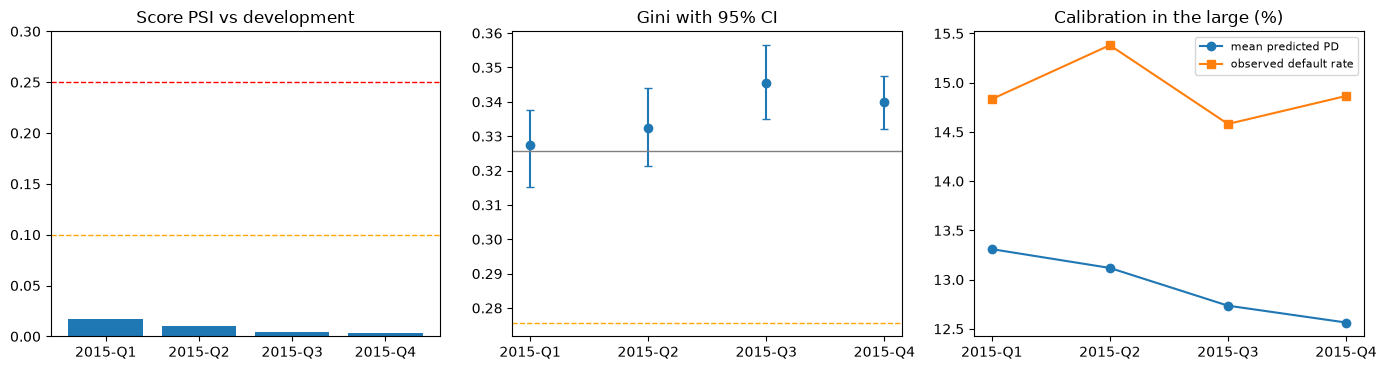

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
x = range(len(quarters))
axes[0].bar(x, rag["score_psi"], color="tab:blue")
axes[0].axhline(0.10, color="orange", ls="--", lw=1)
axes[0].axhline(0.25, color="red", ls="--", lw=1)
axes[0].set(title="Score PSI vs development", ylim=(0, 0.3))
axes[1].errorbar(x, backtesting["gini"], yerr=[backtesting["gini"] - backtesting["gini_ci_low"], backtesting["gini_ci_high"] - backtesting["gini"]], fmt="o", capsize=3)
axes[1].axhline(gini_reference, color="grey", lw=1, label="development")
axes[1].axhline(gini_reference - 0.05, color="orange", ls="--", lw=1)
axes[1].set(title="Gini with 95% CI")
axes[2].plot(x, backtesting["mean_pd_pct"], "o-", label="mean predicted PD")
axes[2].plot(x, backtesting["odr_pct"], "s-", label="observed default rate")
axes[2].set(title="Calibration in the large (%)")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(list(x), quarters)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "04_monitoring_dashboard.png", dpi=150)

## 6. Does the 2014 recalibration fix the problem in 2015?
The intercept shift was estimated on 2014 (notebook 03) and is applied here, unchanged, to data it has never seen. Ranking (Gini) is identical by construction; only the PD level changes.

In [8]:
recalibration = pd.concat({
    "original": pd.DataFrame({q: backtest(g, "pd") for q, g in monitoring.groupby("issue_quarter")}).T,
    "recalibrated": pd.DataFrame({q: backtest(g, "pd_recalibrated") for q, g in monitoring.groupby("issue_quarter")}).T,
}, axis=0)
recalibration["calibration_rag"] = [
    mon.rag_calibration(p, gap / 100)
    for p, gap in zip(recalibration["jeffreys_p"], recalibration["relative_underestimation_pct"])
]
recalibration[["mean_pd_pct", "odr_pct", "relative_underestimation_pct", "jeffreys_p", "grades_amber", "grades_red", "calibration_rag"]].round(4)

mean_pd_pct  odr_pct  relative_underestimation_pct  \
original     2015-Q1      13.3097  14.8335                       11.4483   
             2015-Q2      13.1186  15.3810                       17.2459   
             2015-Q3      12.7354  14.5809                       14.4910   
             2015-Q4      12.5642  14.8651                       18.3130   
recalibrated 2015-Q1      14.0438  14.8335                        5.6227   
             2015-Q2      13.8435  15.3810                       11.1066   
             2015-Q3      13.4425  14.5809                        8.4685   
             2015-Q4      13.2635  14.8651                       12.0753   

                      jeffreys_p  grades_amber  grades_red calibration_rag  
original     2015-Q1         0.0           0.0         6.0             red  
             2015-Q2         0.0           1.0         6.0             red  
             2015-Q3         0.0           2.0         6.0             red  
             2015-Q4         0.0           1.0         7.0             red  
recalibrated 2015-Q1         0.0           3.0         2.0           amber  
             2015-Q2         0.0           0.0         6.0             red  
             2015-Q3         0.0           2.0         4.0           amber  
             2015-Q4         0.0           1.0         6.0             red

## 7. Investigating the worst signal
Order of investigation: (1) data and definitions → (2) population mix → (3) segment concentration → (4) economic and business context → (5) model weakness.

### 7.1 Data and definitions

In [9]:
frames = {"development": pd.concat([train, valid]), "monitoring 2015": monitoring}
status_mix = pd.DataFrame({name: df["loan_status"].value_counts(normalize=True).mul(100) for name, df in frames.items()}).round(2)
missing_shift = pd.DataFrame({name: df[card.features].isna().mean().mul(100) for name, df in frames.items()}).round(2)
display(status_mix)
missing_shift[missing_shift.max(axis=1) > 0]

,development,monitoring 2015
loan_status,,
Charged Off,12.39,14.88
Fully Paid,87.61,85.10
Late (31-120 days),NaN,0.02


,development,monitoring 2015
bc_open_to_buy,0.81,1.00
percent_bc_gt_75,0.81,1.09
mths_since_recent_inq,11.41,11.04
mths_since_recent_bc,0.70,0.96
mo_sin_old_il_acct,4.35,3.52


### 7.2 Population mix
How much of the higher default rate does the model *expect* because of the riskier mix, and how much is unexplained?

In [10]:
dev_all = frames["development"]
dev_pd = card.predict_pd(dev_all).mean()
dev_odr = dev_all[TARGET].mean()
decomposition = pd.Series({
    "development ODR": 100 * dev_odr,
    "2015 ODR": 100 * monitoring[TARGET].mean(),
    "total change (pp)": 100 * (monitoring[TARGET].mean() - dev_odr),
    "explained by population mix (pp)": 100 * (monitoring["pd"].mean() - dev_pd),
    "unexplained (pp)": 100 * (monitoring[TARGET].mean() - monitoring["pd"].mean()) - 100 * (dev_odr - dev_pd),
})
decomposition.round(2)

development ODR                     12.39
2015 ODR                            14.90
total change (pp)                    2.51
explained by population mix (pp)     0.48
unexplained (pp)                     2.03
dtype: float64

### 7.3 Segment concentration
Is the underestimation everywhere, or concentrated? Gap = observed default rate − mean predicted PD, in 2015.

In [11]:
monitoring["lc_grade"] = monitoring["sub_grade"].str[0]
dev_all = dev_all.assign(lc_grade=dev_all["sub_grade"].str[0])

def segment_gap(col: str) -> pd.DataFrame:
    g = monitoring.groupby(col).agg(loans=(TARGET, "size"), odr=(TARGET, "mean"), mean_pd=("pd", "mean"))
    g["share_2015_pct"] = 100 * g["loans"] / g["loans"].sum()
    g["share_dev_pct"] = 100 * dev_all[col].value_counts(normalize=True).reindex(g.index).fillna(0)
    g["gap_pp"] = 100 * (g["odr"] - g["mean_pd"])
    g["contribution_to_total_gap_pp"] = g["gap_pp"] * g["loans"] / g["loans"].sum()
    g[["odr", "mean_pd"]] *= 100
    return g.rename(columns={"odr": "odr_pct", "mean_pd": "mean_pd_pct"}).round(2)

segments = {col: segment_gap(col) for col in ["lc_grade", "purpose", "home_ownership", "verification_status"]}
segments["lc_grade"]

,loans,odr_pct,mean_pd_pct,share_2015_pct,share_dev_pct,gap_pp,contribution_to_total_gap_pp
lc_grade,,,,,,,
A,70107,5.43,7.03,24.79,17.36,-1.60,-0.40
B,91672,11.92,11.71,32.41,40.17,0.21,0.07
C,77363,19.46,15.81,27.35,24.54,3.65,1.00
D,32676,26.23,18.77,11.55,14.28,7.46,0.86
E,9426,32.86,21.40,3.33,3.07,11.46,0.38
F,1360,42.50,24.51,0.48,0.56,17.99,0.09
G,244,46.31,26.95,0.09,0.02,19.36,0.02


In [12]:
for col in ["verification_status", "home_ownership"]:
    display(segments[col])
segments["purpose"].sort_values("loans", ascending=False).head(6)

,loans,odr_pct,mean_pd_pct,share_2015_pct,share_dev_pct,gap_pp,contribution_to_total_gap_pp
verification_status,,,,,,,
Not Verified,83185,11.29,10.95,29.41,39.42,0.35,0.10
Source Verified,119180,14.73,12.76,42.14,20.28,1.97,0.83
Verified,80483,18.88,15.07,28.45,40.31,3.82,1.09


,loans,odr_pct,mean_pd_pct,share_2015_pct,share_dev_pct,gap_pp,contribution_to_total_gap_pp
home_ownership,,,,,,,
MORTGAGE,129636,12.08,10.98,45.83,49.68,1.10,0.50
OTHER,1,0.00,7.67,0.00,0.06,-7.67,-0.00
OWN,31786,15.84,13.74,11.24,8.61,2.10,0.24
RENT,121425,17.67,14.69,42.93,41.65,2.98,1.28


,loans,odr_pct,mean_pd_pct,share_2015_pct,share_dev_pct,gap_pp,contribution_to_total_gap_pp
purpose,,,,,,,
debt_consolidation,160871,15.75,13.61,56.88,57.55,2.14,1.22
credit_card,70607,12.25,10.67,24.96,25.48,1.58,0.39
home_improvement,17150,13.53,9.97,6.06,5.31,3.57,0.22
other,15213,16.85,17.74,5.38,4.69,-0.89,-0.05
major_purchase,5344,14.52,9.85,1.89,1.86,4.67,0.09
medical,3144,17.84,16.98,1.11,0.84,0.86,0.01


### 7.4 Business context: platform growth
Lending Club's 36-month volume grew strongly over this period. Rapid growth can bring in borrowers who look similar on bureau data but behave worse (for example through marketing channels or looser policy) — something no application-data model can see.

In [13]:
context = data.groupby("issue_quarter").agg(
    loans=(TARGET, "size"),
    odr_pct=(TARGET, lambda s: 100 * s.mean()),
    mean_int_rate=("int_rate", "mean"),
    mean_loan_amnt=("loan_amnt", "mean"),
)
context.round(2)

,loans,odr_pct,mean_int_rate,mean_loan_amnt
issue_quarter,,,,
2012-Q4,15181,12.84,13.16,12184.81
2013-Q1,17988,12.59,13.29,13672.03
2013-Q2,23136,12.84,13.74,12250.22
2013-Q3,27318,12.21,13.42,12126.57
2013-Q4,31980,11.91,13.09,12866.29
2014-Q1,34074,12.87,13.02,13128.72
2014-Q2,37881,13.55,12.65,12327.83
2014-Q3,40595,13.63,12.47,12557.90
2014-Q4,50020,14.53,11.94,12433.32


### 7.5 Model weakness: where along each feature does the gap appear?
If the gap were caused by one mis-specified feature, it would be concentrated in a few of its bins. A uniform gap points to a level shift (fixable by recalibration) rather than a broken relationship.

In [14]:
rows = []
for f in card.features:
    tmp = pd.DataFrame({"bin": mon_bins[f].astype(str), "y": monitoring[TARGET], "pd": monitoring["pd"]})
    g = tmp.groupby("bin").agg(loans=("y", "size"), odr=("y", "mean"), mean_pd=("pd", "mean"))
    g = g[g["loans"] >= 1000]
    gap = 100 * (g["odr"] - g["mean_pd"])
    rows.append({"feature": f, "bins": len(g), "min_gap_pp": gap.min(), "max_gap_pp": gap.max(), "bins_with_negative_gap": int((gap < 0).sum())})
feature_gaps = pd.DataFrame(rows).set_index("feature").sort_values("max_gap_pp", ascending=False)
feature_gaps.round(2)

,bins,min_gap_pp,max_gap_pp,bins_with_negative_gap
feature,,,,
acc_open_past_24mths,8,0.49,5.36,0
purpose,4,0.37,3.57,0
dti,8,1.46,3.40,0
fico_mid,8,0.66,3.29,0
mths_since_recent_inq,9,1.12,3.19,0
mo_sin_rcnt_tl,8,0.88,3.15,0
mths_since_recent_bc,8,-0.23,3.10,1
mo_sin_old_il_acct,8,1.21,2.83,0
annual_inc,8,1.03,2.81,0


## 8. SQL cross-check
The same quarterly back-testing and PSI computed in DuckDB SQL (`sql/03_monitoring_tables.sql`) from a scored-loans table. Both implementations must agree.

In [15]:
scored_path = config.PROCESSED_DIR / "scored_monitoring.parquet"
pd.concat([
    pd.DataFrame({"sample": "reference", "issue_quarter": train["issue_quarter"], "bad_flag": train[TARGET], "pd": pd_reference}),
    monitoring.assign(sample="monitoring")[["sample", "issue_quarter", TARGET, "pd", "grade"]],
]).assign(
    score_bin=lambda d: val.assign_grades(d["pd"], psi_edges),
).to_parquet(scored_path, index=False)

con = sql_connection(config.SQL_DIR / "03_monitoring_tables.sql", scored_path=scored_path.as_posix())
sql_psi = con.sql("SELECT * FROM mon_score_psi").df().set_index("issue_quarter")["psi"]
sql_quarterly = con.sql("SELECT * FROM mon_quarterly").df().set_index("issue_quarter")
check = pd.DataFrame({
    "psi_python": score_psi, "psi_sql": sql_psi,
    "odr_python": backtesting["odr_pct"] / 100, "odr_sql": sql_quarterly["odr"],
})
print("max abs difference:", float((check["psi_python"] - check["psi_sql"]).abs().max()), float((check["odr_python"] - check["odr_sql"]).abs().max()))
check.round(6)

max abs difference: 3.469446951953614e-18 2.7755575615628914e-17


,psi_python,psi_sql,odr_python,odr_sql
2015-Q1,0.016910,0.016910,0.148335,0.148335
2015-Q2,0.010641,0.010641,0.153810,0.153810
2015-Q3,0.004710,0.004710,0.145809,0.145809
2015-Q4,0.003353,0.003353,0.148651,0.148651


In [16]:
rag.to_csv(config.REPORTS_DIR / "monitoring_rag_2015.csv")
backtesting.to_csv(config.REPORTS_DIR / "monitoring_backtesting_2015.csv")
csi.to_csv(config.REPORTS_DIR / "monitoring_csi_2015.csv")
recalibration.to_csv(config.REPORTS_DIR / "monitoring_recalibration_2015.csv")

## 9. Findings

1. **Front-end stability is green every quarter.** Score PSI 0.003–0.017 (amber threshold 0.10); the largest feature CSI is 0.08 (`percent_bc_gt_75`, slowly rising). The 2015 applicants look like the development applicants on paper.
2. **Discrimination is green.** Gini 0.33–0.35 per quarter, at or slightly above the development level (0.326). The model still ranks borrowers correctly.
3. **Calibration is red every quarter.** Observed default rate 14.6–15.4% vs mean predicted PD 12.6–13.3%: PD underestimated by 11–18%, and in 6–7 of 8 grades per quarter. Predicted PD *falls* through 2015 while observed defaults do not.
4. **Lesson: green stability does not mean the model is fine.** PSI/CSI only detect changes in the *inputs*. Here the inputs are stable but the relationship between inputs and outcome has shifted (concept drift), which only back-testing can reveal.
5. **Time lag.** Front-end metrics are available at quarter end. Back-testing is not: 12 months after issue only ~35% of eventual defaulters have stopped paying, ~78% after 24 months. In real time this red signal would have emerged gradually during 2016–2017, not at the end of 2015.
6. **The 2014 recalibration helps but is not enough.** It roughly halves the gap (to 6–12%) but two quarters stay red. It is also optimistic: in reality the 2014 outcomes needed to estimate it would not be complete until 2017.
7. **Implementation check.** The SQL monitoring layer (`sql/03_monitoring_tables.sql`) reproduces the Python PSI and default rates to within 1e-17.

---

## Monitoring finding — 2015 portfolio (half-page summary)

**Signal.** Calibration red in all four 2015 quarters: PD underestimated by 11–18% (Jeffreys p < 0.001). Stability and discrimination green.

**Investigation.**
1. *Data and definitions* — no change: same default definition and statuses, 0.03% unresolved loans, no new categories, missingness of model features changed by less than 1 percentage point. Not a data problem.
2. *Population mix* — explains little: of the +2.5 pp rise in default rate versus development, only +0.5 pp is expected from the borrowers' features; **+2.0 pp is unexplained**.
3. *Segment concentration* — the gap is not uniform. By Lending Club's own grade it runs from −1.6 pp (grade A, risk over-estimated) to +3.7 pp (C), +7.5 pp (D) and +11–19 pp (E–G). Within each LC grade our model's PD spreads too little: LC's grading captured a 2015 risk difference that our application features do not. Verified and source-verified income loans and renters contribute most of the gap; the share of "Source Verified" loans doubled (20% → 42%), suggesting a change in LC's verification process.
4. *Business and economic context* — LC's 36-month volume grew almost six-fold (15k loans in 2012-Q4 → 88k in 2015-Q4) while its average interest rate fell from ~13% to ~11%. Rapid growth with cheaper pricing is a classic setting for adverse selection. US unemployment continued to fall during 2015, so a general economic downturn is an unlikely explanation.
5. *Model weakness* — the gap is positive in almost every bin of every feature (only 3 of 103 bins slightly negative), so no single feature is broken; the model's relationships hold in direction but the risk level and the spread between high- and low-risk segments have changed.

**Conclusion.** A genuine change in risk not visible in the model's inputs, most likely linked to the lender's growth, pricing and verification changes — not a data error.

**Recommended actions** (owner: model owner, with credit risk management):
1. Short term: apply a documented PD overlay. A portfolio-level intercept shift is not sufficient; a segment-level add-on (by LC grade or verification status) should be evaluated.
2. Escalate the red calibration status and the size of the underestimation for its effect on provisions/expected loss (see notebook 05).
3. Medium term: redevelop on recent vintages and test the features the scorecard excluded (the challenger gained 3.8 Gini points from them).
4. Add an early-read back-test (e.g. 12-month default rate by vintage) so the next signal arrives in about a year instead of three.